Домашнее задание по теме 3

$\textbf{Часть 1}$

a) напишите формулу для моделирования второй выборки; 

Напишем формулу обратной функции распределения для второй выборки:
$$y=F(x)=x^2 → x=\sqrt{y}$$

In [2]:
import numpy as np

np.random.seed(12345)
X_1 = np.random.uniform(low=0,high=1,size=50)
Y = np.random.uniform(low=0,high=1,size=50)
X_2 = np.sqrt(Y)

б) постройте графики эмпирических функций распределения

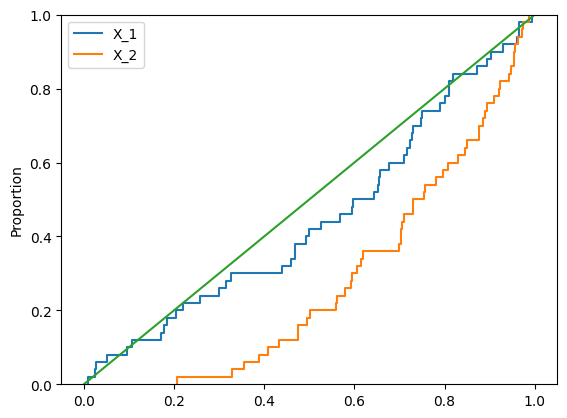

In [8]:
import matplotlib.pyplot as plt
import seaborn as sb

sb.ecdfplot(X_1,label='X_1')
sb.ecdfplot(X_2,label='X_2')
plt.plot([0,1],[0,1])
plt.legend()
plt.show()

в) укажите p-value критериев Колмогорова и Крамера — фон Мизеса и сделайте выводы, отвергается 
ли на уровне 0,05 гипотеза равномерности для каждой из выборок.

In [29]:
from scipy import stats

p_KS_1 = stats.kstest(X_1, 'uniform', args=(0,1)).pvalue
p_KS_2 = stats.kstest(X_2, 'uniform', args=(0,1)).pvalue
print(p_KS_1)
print(p_KS_2)

0.23839990531149569
2.733996809343027e-06


In [28]:
p_CVM_1 = stats.cramervonmises(X_1, 'uniform', args=(0,1)).pvalue
p_CVM_2 = stats.cramervonmises(X_2, 'uniform', args=(0,1)).pvalue
print(p_CVM_1)
print(p_CVM_2)

0.21323687196636387
3.626033073800272e-08


Итог: оба критерия не смогли отвергнуть гипотезу для первой выборки, но оба смогли отвергнуть гипотезу для второй выборки.

$\textbf{Часть 2}$

Посмотроим график плотности

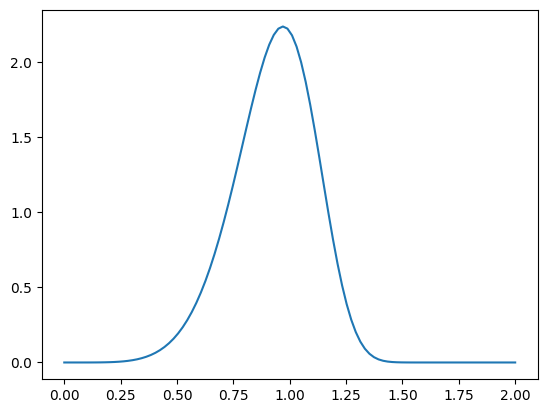

In [2]:
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0,2,100)
f_x = stats.weibull_min.pdf(x, c=6, scale=1)
plt.plot(x,f_x)
plt.show()

График плотности не симметричен

In [6]:
np.random.seed(12345)
x = stats.weibull_min.rvs(size=100, c=6, scale=1)

Визуальный анализ 

а) постройте гистограмму

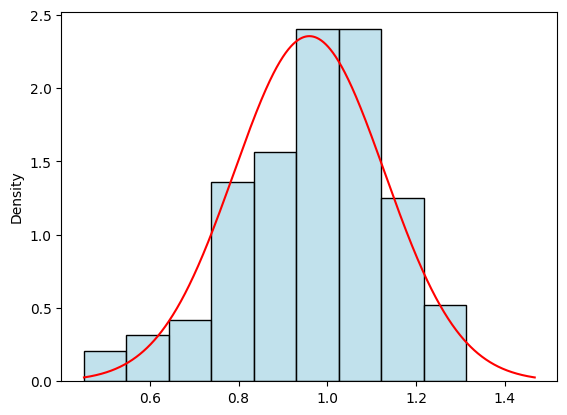

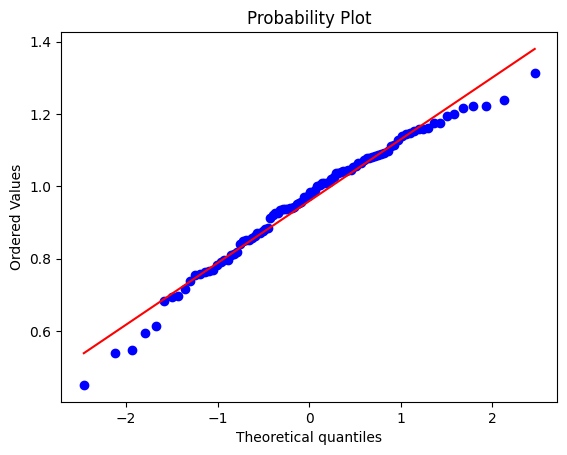

In [8]:
from scipy.stats import norm, probplot 
import seaborn as sb

n=len(x); mu=np.mean(x); s=np.std(x); u=np.linspace(mu - 3*s, mu + 3*s, 1000)  
sb.histplot(x, stat='density', color='lightblue')       
plt.plot(u, norm.pdf(u, mu, s), color='red')            
plt.show(); probplot(x, plot=plt); plt.show()          


Наблюдается перекос в гистограмме 

б) укажите значения G1, G2, B, а также p-value критериев Д′Агостино и Шапиро — Уилка;

In [11]:
from scipy.stats import skew, kurtosis, skewtest, kurtosistest, shapiro


g1=skew(x); g2=kurtosis(x); b=n*g1**2; print('G1 =', g1, 'G2 =', g2, 'B =', b) 

G1 = -0.555290189660002 G2 = 0.09137899093423218 B = 30.834719473264098


$B>6, G_1<0$, применяем skewtest с alternative='less':

In [15]:
_, p = skewtest(x, alternative='less')
print('p_value=',p)

p_value= 0.011214020700888883


На уровне 0.05 мы можем отвергнуть гипотезу о симметричности распределения.

Посмотрим еще на тест Шапиро-Уилка:

In [17]:
_, p = shapiro(x)
print('p_value=',p)

p_value= 0.07562964079765164


в) ответьте, отвергается ли гипотеза о нормальности распределения наблюдений на уровне 0,05. 

На уровне 0.05 мы можем отвергнуть нормальность, т.к. на этом уровне мы отвергли симметрию, что является необходимым для нормальности.